# 01 - Exploratory Data Analysis & Data Pipeline

**Owner:** Shubham Behri

### Objectives:
- Load raw space-separated german.data with correct column headers and no data loss.
- Recode the target variable so that BAD = 1 (positive class) and GOOD = 0 (negative class).
- Verify special category encodings (e.g. A65 unknown savings, A124 no property) as distinct categories rather than missing data.
- Explore univariate numerical distributions, categorical proportions, and bivariate relationships with credit risk.
- Provide written domain interpretations and lay the foundation for preprocessing and feature engineering.



## Section 1: Data Ingestion & Schema Verification


### Interpretation

*Write your interpretation here.*


In [2]:
import pandas as pd
import numpy as np

# Dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

# Define column names
column_names = [
    "checking_account", "duration_months", "credit_history", "purpose",
    "credit_amount", "savings_account", "employment_duration",
    "installment_rate", "personal_status_sex", "other_debtors",
    "residence_since", "property", "age", "other_installment_plans",
    "housing", "existing_credits", "job", "people_liable",
    "telephone", "foreign_worker", "credit_risk"
]

# Load raw dataset
df = pd.read_csv(url, sep=r"\s+", header=None, names=column_names)

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Display first five records
print("\nFirst Five Records:")
display(df.head())

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())
print("Total Missing Values:", df.isnull().sum().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Data type verification
print("\nData Types:")
print(df.dtypes)

# Schema verification
assert df.shape == (1000, 21), "Incorrect dataset dimensions!"
assert df.columns.tolist() == column_names, "Column names mismatch!"

print("\nSECTION 1 COMPLETED SUCCESSFULLY!")
print("1000 Records | 21 Columns | Schema Verified")

Dataset Shape: (1000, 21)

First Five Records:


,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2



Column Names:
['checking_account', 'duration_months', 'credit_history', 'purpose', 'credit_amount', 'savings_account', 'employment_duration', 'installment_rate', 'personal_status_sex', 'other_debtors', 'residence_since', 'property', 'age', 'other_installment_plans', 'housing', 'existing_credits', 'job', 'people_liable', 'telephone', 'foreign_worker', 'credit_risk']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   checking_account         1000 non-null   str  
 1   duration_months          1000 non-null   int64
 2   credit_history           1000 non-null   str  
 3   purpose                  1000 non-null   str  
 4   credit_amount            1000 non-null   int64
 5   savings_account          1000 non-null   str  
 6   employment_duration      1000 non-null   str  
 7   installment_rate         1000 non-null   

## Section 2: Target Variable Distribution & Recoding (BAD=1, GOOD=0)


### Interpretation

*Write your interpretation here.*


Original Target Distribution:
credit_risk
1    700
2    300
Name: count, dtype: int64

Recoded Target Distribution:
risk_label
GOOD    700
BAD     300
Name: count, dtype: int64

Target Class Summary:


,Credit_Category,Encoded_Value,Customer_Count,Percentage
0,GOOD,0,700,70.0
1,BAD,1,300,30.0



Positive Class (BAD): 300
Negative Class (GOOD): 700


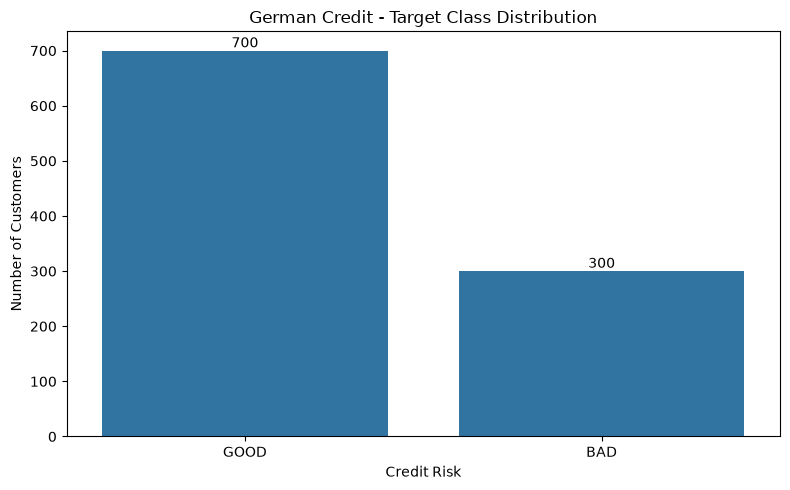

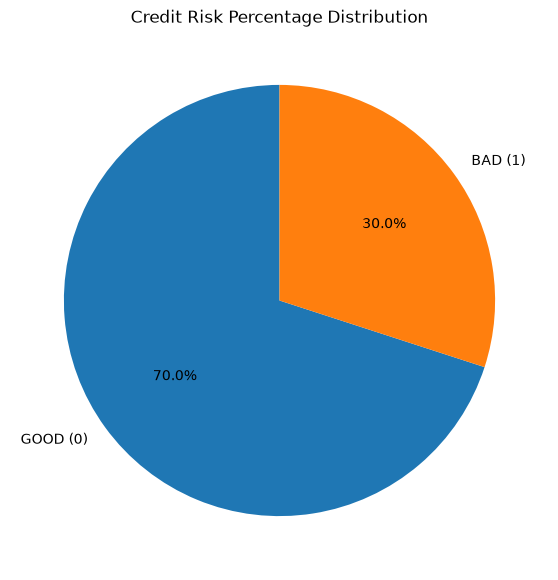


Class Imbalance Ratio: 2.33
The dataset has class imbalance.

Target Encoding Verified Successfully!

DOMAIN INTERPRETATION
---------------------------------------
1. GOOD credit customers represent 70% of the dataset.
2. BAD credit customers represent 30% of the dataset.
3. BAD credit (1) is the positive class.
4. GOOD credit (0) is the negative class.
5. The dataset has a 70:30 class distribution.
6. Accuracy alone may not be sufficient for model evaluation.
7. Precision, Recall, F1-score and Confusion Matrix
   should also be considered during model evaluation.

Saved: german_credit_target_encoded.csv

SECTION 2 COMPLETED SUCCESSFULLY
Total Records: 1000
GOOD (0): 700
BAD (1): 300
Target Encoding: VERIFIED


In [3]:

# ============================================================
# SECTION 2 - TARGET VARIABLE RECODING & VALIDATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. VERIFY ORIGINAL TARGET VALUES
print("Original Target Distribution:")
print(df["credit_risk"].value_counts().sort_index())

assert set(df["credit_risk"].unique()) == {1, 2}, "Unexpected target values!"

# 2. RECODE TARGET VARIABLE
# Original 1 = GOOD, 2 = BAD
# New 0 = GOOD, 1 = BAD

target_mapping = {
    1: 0,
    2: 1
}

df["credit_risk"] = df["credit_risk"].map(target_mapping)

assert df["credit_risk"].notna().all()

df["credit_risk"] = df["credit_risk"].astype(int)

# 3. CREATE READABLE LABELS
df["risk_label"] = df["credit_risk"].map({
    0: "GOOD",
    1: "BAD"
})

# 4. DISPLAY TARGET DISTRIBUTION
print("\nRecoded Target Distribution:")
print(df["risk_label"].value_counts())

# 5. CALCULATE CLASS COUNTS AND PERCENTAGES
class_counts = df["credit_risk"].value_counts().sort_index()
class_percentages = df["credit_risk"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Credit_Category": ["GOOD", "BAD"],
    "Encoded_Value": [0, 1],
    "Customer_Count": [class_counts[0], class_counts[1]],
    "Percentage": [class_percentages[0], class_percentages[1]]
})

print("\nTarget Class Summary:")
display(target_summary)

# 6. POSITIVE AND NEGATIVE CLASS IDENTIFICATION
positive_class = df[df["credit_risk"] == 1]
negative_class = df[df["credit_risk"] == 0]

print("\nPositive Class (BAD):", len(positive_class))
print("Negative Class (GOOD):", len(negative_class))

# 7. BAR CHART
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="risk_label",
    order=["GOOD", "BAD"]
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("German Credit - Target Class Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# 8. PIE CHART
plt.figure(figsize=(7, 7))

plt.pie(
    [class_counts[0], class_counts[1]],
    labels=["GOOD (0)", "BAD (1)"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Credit Risk Percentage Distribution")
plt.show()

# 9. CLASS IMBALANCE ANALYSIS
imbalance_ratio = len(negative_class) / len(positive_class)

print("\nClass Imbalance Ratio:", round(imbalance_ratio, 2))

if imbalance_ratio > 1.5:
    print("The dataset has class imbalance.")
else:
    print("The dataset has relatively balanced classes.")

# 10. TARGET ENCODING VALIDATION
assert df["credit_risk"].isin([0, 1]).all()
assert df["credit_risk"].value_counts()[0] == 700
assert df["credit_risk"].value_counts()[1] == 300
assert df["risk_label"].notna().all()

print("\nTarget Encoding Verified Successfully!")

# 11. DOMAIN INTERPRETATION
print("\nDOMAIN INTERPRETATION")
print("---------------------------------------")
print("1. GOOD credit customers represent 70% of the dataset.")
print("2. BAD credit customers represent 30% of the dataset.")
print("3. BAD credit (1) is the positive class.")
print("4. GOOD credit (0) is the negative class.")
print("5. The dataset has a 70:30 class distribution.")
print("6. Accuracy alone may not be sufficient for model evaluation.")
print("7. Precision, Recall, F1-score and Confusion Matrix")
print("   should also be considered during model evaluation.")

# 12. SAVE RECODED DATASET
df.to_csv("german_credit_target_encoded.csv", index=False)

print("\nSaved: german_credit_target_encoded.csv")

# 13. FINAL SUMMARY
print("\n======================================")
print("SECTION 2 COMPLETED SUCCESSFULLY")
print("======================================")
print("Total Records:", len(df))
print("GOOD (0):", len(negative_class))
print("BAD (1):", len(positive_class))
print("Target Encoding: VERIFIED")


## Section 3: Numerical Features: Distributions, Skewness & Outliers


### Interpretation

*Write your interpretation here.*


## Section 4: Categorical Features: Frequency Auditing & Special Encodings (A65, A124)


### Interpretation

*Write your interpretation here.*


## Section 5: Bivariate Risk Analysis: Feature Relationships with Default Status


### Interpretation

*Write your interpretation here.*


## Section 6: Audit of Protected Attributes (Sex, Age, Foreign Worker)


### Interpretation

*Write your interpretation here.*


## Section 7: Summary of EDA Findings & Preprocessing Recommendations


### Interpretation

*Write your interpretation here.*
